In [17]:
import numpy as np
import pandas as pd
from src.data_loader import *
from torchvision import transforms
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Carregamento dos dados:

In [2]:
root = "pa3_dados"

In [3]:
dim_classes = pd.read_csv(f"{root}/classes.csv")

In [4]:
y_train = get_labels(root, labels_qtt=5)
y_val   = get_labels(root, file_name="val")
y_test  = get_labels(root, file_name="test_public")


y_train_map = {
    k: v["label"]
    for k, v in y_train.set_index("image_id").to_dict(orient="index").items()
}

y_val_map = {
    k: v["label"]
    for k, v in y_val.set_index("image_id").to_dict(orient="index").items()
}

y_test_map = {
    k: v["label"]
    for k, v in y_test.set_index("image_id").to_dict(orient="index").items()
}

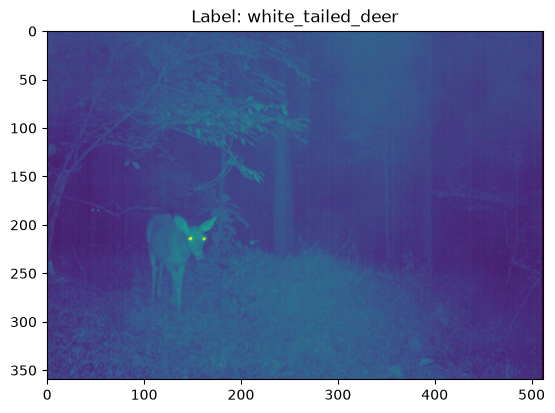

In [5]:
transform_unsupervised = transforms.Compose([
    transforms.Resize((360, 512)), # Resize para um dimensionamento padrao
    transforms.ToTensor(),
    transforms.Grayscale()
])

# Instancia os Datasets de treino, validacao e teste
train_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='train', 
    transform=transform_unsupervised
)
val_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='val', 
    transform=transform_unsupervised
)
test_dataset = ENA24UnsupervisedDataset(
    root_dir=root, 
    split='test_public', 
    transform=transform_unsupervised
)

# Cria os DataLoaders
loader_params = {
    "batch_size": 16, 
    "shuffle": True,  # Para treino, embaralhamos os dados
    "num_workers": 2, 
}
train_loader = DataLoader(train_dataset, **loader_params)
val_loader   = DataLoader(val_dataset, **loader_params)
test_loader  = DataLoader(test_dataset, **loader_params)


# Testando um batch
find = False
for images, image_ids in train_loader:
    for image, image_id in zip(images, image_ids):
        label = y_train_map.get(image_id, None)
        if label:
            image = image.numpy().transpose((1, 2, 0))
            image = np.clip(image, 0, 1)
            plt.imshow(image)
            plt.title(f"Label: {label}")
            find = True
            break
        
    if find:
        break

# Parte 0 — O piso:

### 0.0: Carregamento dos dados de treino (Supervisionados)

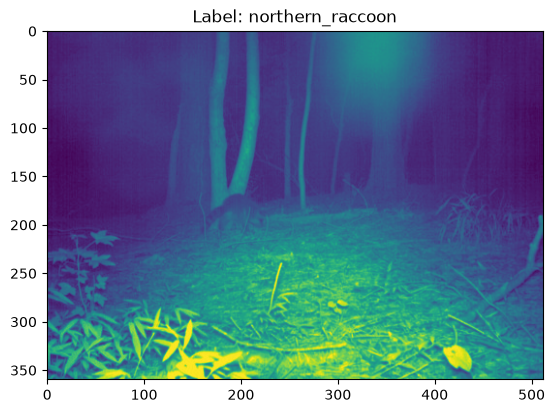

In [20]:
transform_supervised = transforms.Compose([
    transforms.Resize((360, 512)), # Resize para um dimensionamento padrao
    transforms.ToTensor(),
    transforms.Grayscale()
])

# Instancia o Datasets supervisionado de treino com 5 rotulos por classe
# (somente as imagens com labels)
# Validacao e teste ja vem com labels em todas as imagens.
train_5_sup_dataset = ENA24SupervisedDataset(
    root_dir=root, 
    labels_qtt=5, 
    split='train', 
    transform=transform_supervised
)

# Cria os DataLoaders
loader_params = {
    "batch_size": 16, 
    "shuffle": True,  # Para treino, embaralhamos os dados
    "num_workers": 2, 
}
train_5_sup_loader = DataLoader(train_5_sup_dataset, **loader_params)


# Testando um batch
for images, labels in train_5_sup_loader:
    label = labels[0]
    image = images[0].numpy().transpose((1, 2, 0))
    image = np.clip(image, 0, 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    break

### 0.1: Treinem um classificador supervisionado só com rotulos_5.csv (105 imagens), em duas versões: 

#### (a) uma CNN pequena treinada do zero; 

#### (b) o backbone que vocês vão usar no resto do PA, partindo do ImageNet, com fine-tuning.

### 0.2: 

#### (a) Reportem F1 macro e acurácia no test_public, mais a matriz de confusão da versão.

#### (b). A métrica principal do PA é o F1 macro, que pesa cavalo igual a urso; acurácia sozinha esconde as classes raras.

### 0.3: 

#### (a) Mostrem a curva de treino e validação da versão. 

#### (b). Com 105 imagens, em que época ela começa a decorar?

# Parte 1 — Usando o que não tem rótulo (escolham UMA trilha):